In [ ]:
from pathlib import Path
import torch
from torchvision.models import vgg16

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Load the pretrained VGG-16 weights.
model = vgg16(weights=None)
weights_path = Path("checkpoints/pretrained_vgg.pt")
state_dict = torch.load(
    weights_path, map_location="cpu", weights_only=True
)
model.load_state_dict(state_dict)

# Keep only the convolutional layers and freeze them.
encoder = model.features
encoder.requires_grad_(False)
encoder.eval()
encoder = encoder.to(device)

del model, state_dict

# Check the output dimensions with a dummy image.
with torch.inference_mode():
    features = encoder(torch.zeros(1, 3, 224, 224, device=device))
    image_vector = features.mean(dim=(2, 3))


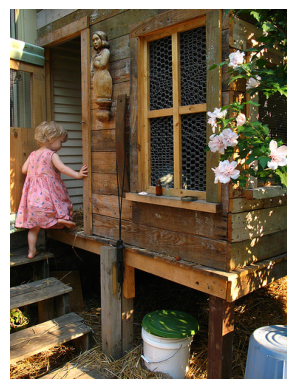

In [6]:
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt

data_dir = Path("data/flickr8k")
image_dir = data_dir / "Flicker8k_Dataset"

captions = defaultdict(list)

with open(data_dir / "Flickr8k.token.txt", encoding="utf-8") as f:
    for line in f:
        image_id, caption = line.strip().split("\t", 1)
        filename = image_id.rsplit("#", 1)[0]
        captions[filename].append(caption)

filename = next(iter(captions))

plt.imshow(Image.open(image_dir / filename).convert("RGB"))
plt.axis("off")
plt.show()


In [27]:
import shutil

checkpoint_dir = Path("checkpoints")
baseline_path = checkpoint_dir / "baseline_3000.pt"

if not baseline_path.exists():
    shutil.copy2(
        checkpoint_dir / "best_caption_decoder.pt",
        baseline_path,
    )

baseline = torch.load(
    baseline_path,
    map_location="cpu",
    weights_only=True,
)

In [28]:
import random

def load_split(filename):
    with open(data_dir / filename) as f:
        names = [line.strip() for line in f if line.strip()]

    return [
        name for name in names
        if name in captions and (image_dir / name).is_file()
    ]

train_images = load_split("Flickr_8k.trainImages.txt")
val_images = baseline["val_images"]
test_images = baseline["test_images"]

assert set(train_images).isdisjoint(val_images)
assert set(train_images).isdisjoint(test_images)
assert set(val_images).isdisjoint(test_images)

In [29]:
import re
from collections import Counter

def tokenize(caption):
    return re.findall(r"[a-z]+", caption.lower())

word_counts = Counter(
    word
    for filename in train_images
    for caption in captions[filename]
    for word in tokenize(caption)
)

vocab = ["<pad>", "<bos>", "<eos>", "<unk>"] + sorted(
    word for word, count in word_counts.items() if count >= 2
)

word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

PAD_ID, BOS_ID, EOS_ID, UNK_ID = range(4)
MAX_WORDS = 25

def encode_caption(caption):
    words = tokenize(caption)[:MAX_WORDS]
    return (
        [BOS_ID]
        + [word_to_idx.get(word, UNK_ID) for word in words]
        + [EOS_ID]
    )


In [65]:
import torch.nn as nn
class SpatialAttention(nn.Module):
    def __init__(
        self,
        feature_dim=512,
        hidden_dim=256,
        attention_dim=128,
    ):
        super().__init__()
        self.feature_projection = nn.Linear(
            feature_dim, attention_dim
        )
        self.hidden_projection = nn.Linear(
            hidden_dim, attention_dim, bias=False
        )
        self.score_projection = nn.Linear(
            attention_dim, 1, bias=False
        )
    def forward(self, spatial_features, hidden_state):
        projected_features = self.feature_projection(
            spatial_features
        )

        projected_hidden = self.hidden_projection(
            hidden_state
        ).unsqueeze(1)

        scores = self.score_projection(
            torch.tanh(projected_features + projected_hidden)
        ).squeeze(-1)

        weights = torch.softmax(scores, dim=1)

        context = (
            spatial_features * weights.unsqueeze(-1)
        ).sum(dim=1)

        return context, weights

In [78]:
import torch.nn as nn

class CaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        image_dim=128,
        hidden_dim=256,
        attention_dim=128,
        dropout=0.3,
    ):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD_ID
        )
        self.embedding_dropout = nn.Dropout(dropout)
        self.output_dropout = nn.Dropout(dropout)

        self.attention = SpatialAttention(
            feature_dim=512,
            hidden_dim=hidden_dim,
            attention_dim=attention_dim,
        )
        

        self.context_projection = nn.Sequential(
            nn.Linear(512, image_dim),
            nn.ReLU(),
        )

        self.lstm = nn.LSTMCell(
            input_size=embed_dim + image_dim,
            hidden_size=hidden_dim,
        )

        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, spatial_features, input_tokens, state=None):
        batch_size, sequence_length = input_tokens.shape

        if state is None:
            hidden = spatial_features.new_zeros(
                batch_size, self.hidden_dim
            )
            cell = spatial_features.new_zeros(
                batch_size, self.hidden_dim
            )
        else:
            hidden, cell = state

        embeddings = self.embedding_dropout(
            self.embedding(input_tokens)
        )
        predictions = []

        for t in range(sequence_length):
            context, _ = self.attention(spatial_features, hidden)
            image_embedding = self.context_projection(context)

            step_input = torch.cat(
                [embeddings[:, t, :], image_embedding],
                dim=-1,
            )

            hidden, cell = self.lstm(
                step_input, (hidden, cell)
            )

            predictions.append(
            self.output(self.output_dropout(hidden))
        )

        logits = torch.stack(predictions, dim=1)

        return logits, (hidden, cell)

In [50]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class ImageDataset(Dataset):
    def __init__(self, filenames):
        self.filenames = filenames

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        filename = self.filenames[index]
        with Image.open(image_dir / filename) as image:
            image = preprocess(image.convert("RGB"))
        return filename, image


feature_dir = Path("features")
feature_dir.mkdir(exist_ok=True)
cache_path = feature_dir / "vgg16_spatial.pt"

selected_images = sorted(
    set(train_images + val_images + test_images)
)

if cache_path.exists():
    image_features = torch.load(
        cache_path, map_location="cpu", weights_only=True
    )
else:
    image_features = {}

missing_images = sorted(set(selected_images) - set(image_features))

if missing_images:
    loader = DataLoader(
        ImageDataset(missing_images),
        batch_size=8,
        shuffle=False,
        num_workers=0,
    )

    encoder.eval()

    with torch.inference_mode():
        for filenames, images in loader:
            spatial_features = encoder(images.to(device)).cpu()

            for filename, feature in zip(filenames, spatial_features):
                image_features[filename] = feature.clone()

    torch.save(image_features, cache_path)

In [79]:
from torch.nn.utils.rnn import pad_sequence


class CaptionDataset(Dataset):
    def __init__(self, filenames):
        self.pairs = [
            (filename, caption)
            for filename in filenames
            for caption in captions[filename]
        ]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        filename, caption = self.pairs[index]

        spatial_features = (
            image_features[filename]
            .flatten(start_dim=1)
            .transpose(0, 1)
            .contiguous()
        )

        tokens = torch.tensor(
            encode_caption(caption), dtype=torch.long
        )

        return spatial_features, tokens


def collate_captions(batch):
    image_vectors, token_sequences = zip(*batch)

    image_vectors = torch.stack(image_vectors)

    input_tokens = pad_sequence(
        [tokens[:-1] for tokens in token_sequences],
        batch_first=True,
        padding_value=PAD_ID,
    )

    target_tokens = pad_sequence(
        [tokens[1:] for tokens in token_sequences],
        batch_first=True,
        padding_value=PAD_ID,
    )

    return image_vectors, input_tokens, target_tokens


train_loader = DataLoader(
    CaptionDataset(train_images),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_captions,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

val_loader = DataLoader(
    CaptionDataset(val_images),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_captions,
    num_workers=0,
)

In [80]:
import time

torch.manual_seed(42)

decoder = CaptionDecoder(vocab_size=len(vocab)).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.Adam(decoder.parameters(), lr=1e-3)

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)
model_path = checkpoint_dir / "caption_decoder_attention_dropout.pt"

In [81]:
def run_epoch(loader, training):
    decoder.train(training)

    total_loss = 0.0
    total_correct = 0
    total_tokens = 0

    with torch.set_grad_enabled(training):
        for image_vectors, input_tokens, target_tokens in loader:
            image_vectors = image_vectors.to(device)
            input_tokens = input_tokens.to(device)
            target_tokens = target_tokens.to(device)

            if training:
                optimizer.zero_grad()

            logits, _ = decoder(image_vectors, input_tokens)

            loss = criterion(
                logits.reshape(-1, len(vocab)),
                target_tokens.reshape(-1),
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    decoder.parameters(), max_norm=5.0
                )
                optimizer.step()

            mask = target_tokens != PAD_ID
            token_count = mask.sum().item()

            predictions = logits.argmax(dim=-1)
            correct = ((predictions == target_tokens) & mask).sum().item()

            total_loss += loss.item() * token_count
            total_correct += correct
            total_tokens += token_count

    return (
        total_loss / total_tokens,
        100 * total_correct / total_tokens,
    )

In [82]:
EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    elapsed = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "seconds": elapsed,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.3f}, acc {train_acc:.1f}% | "
        f"val loss {val_loss:.3f}, acc {val_acc:.1f}% | "
        f"{elapsed:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state": {
                name: tensor.detach().cpu()
                for name, tensor in decoder.state_dict().items()
            },
            "model_config": {
            "vocab_size": len(vocab),
            "embed_dim": 128,
            "image_dim": 128,
            "hidden_dim": 256,
            "attention_dim": 128,
            "dropout": 0.3,
        },
            "vocab": vocab,
            "max_words": MAX_WORDS,
            "train_images": train_images,
            "val_images": val_images,
            "test_images": test_images,
            "epoch": epoch,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
        },model_path)

    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01 | train loss 4.289, acc 27.3% | val loss 3.588, acc 32.9% | 39.1s
Epoch 02 | train loss 3.443, acc 34.3% | val loss 3.266, acc 35.8% | 38.9s
Epoch 03 | train loss 3.159, acc 36.6% | val loss 3.130, acc 36.9% | 39.3s
Epoch 04 | train loss 2.981, acc 38.1% | val loss 3.061, acc 37.4% | 38.5s
Epoch 05 | train loss 2.849, acc 39.5% | val loss 3.019, acc 37.9% | 38.1s
Epoch 06 | train loss 2.748, acc 40.4% | val loss 3.002, acc 38.3% | 38.8s
Epoch 07 | train loss 2.661, acc 41.3% | val loss 2.982, acc 38.6% | 39.4s
Epoch 08 | train loss 2.591, acc 42.1% | val loss 2.983, acc 38.6% | 38.8s
Epoch 09 | train loss 2.528, acc 42.8% | val loss 3.001, acc 38.7% | 39.3s
Epoch 10 | train loss 2.472, acc 43.5% | val loss 3.005, acc 38.9% | 41.6s
Epoch 11 | train loss 2.422, acc 44.0% | val loss 3.009, acc 38.9% | 43.1s
Early stopping.


In [97]:
checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True,
)

decoder = CaptionDecoder(**checkpoint["model_config"]).to(device)
decoder.load_state_dict(checkpoint["model_state"])
decoder.eval()

saved_vocab = checkpoint["vocab"]
saved_word_to_idx = {
    word: idx for idx, word in enumerate(saved_vocab)
}


@torch.inference_mode()
def generate_caption(filename, beam_size=3, length_alpha=0.6):
    spatial_features = (
        image_features[filename]
        .flatten(start_dim=1)
        .transpose(0, 1)
        .contiguous()
        .unsqueeze(0)
        .to(device)
    )

    bos_id = saved_word_to_idx["<bos>"]
    eos_id = saved_word_to_idx["<eos>"]
    pad_id = saved_word_to_idx["<pad>"]

    beams = [([bos_id], 0.0, None)]

    def normalized_score(candidate):
        tokens, log_probability, _ = candidate
        length = len(tokens) - 1
        penalty = ((5 + length) / 6) ** length_alpha
        return log_probability / penalty

    for _ in range(checkpoint["max_words"] + 1):
        candidates = []

        for tokens, log_probability, state in beams:
            if tokens[-1] == eos_id:
                candidates.append((tokens, log_probability, state))
                continue

            token = torch.tensor(
                [[tokens[-1]]],
                dtype=torch.long,
                device=device,
            )

            logits, next_state = decoder(
                spatial_features, token, state
            )

            scores = logits[:, -1, :].clone()
            scores[:, pad_id] = -torch.inf
            scores[:, bos_id] = -torch.inf

            log_probs = torch.log_softmax(scores, dim=-1)
            top_probs, top_ids = log_probs.topk(
                beam_size, dim=-1
            )

            for word_log_prob, word_id in zip(
                top_probs[0].tolist(),
                top_ids[0].tolist(),
            ):
                candidates.append((
                    tokens + [word_id],
                    log_probability + word_log_prob,
                    next_state,
                ))

        beams = sorted(
            candidates,
            key=normalized_score,
            reverse=True,
        )[:beam_size]

        if all(tokens[-1] == eos_id for tokens, _, _ in beams):
            break

    best_tokens, _, _ = max(beams, key=normalized_score)

    words = []
    for token_id in best_tokens[1:]:
        if token_id == eos_id:
            break
        words.append(saved_vocab[token_id])

    return " ".join(words)

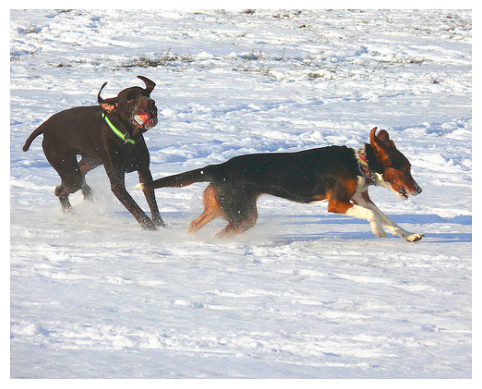

Generated: two dogs play in the snow
Reference: The dog with the green collar and ball is running behind the dog with the red collar


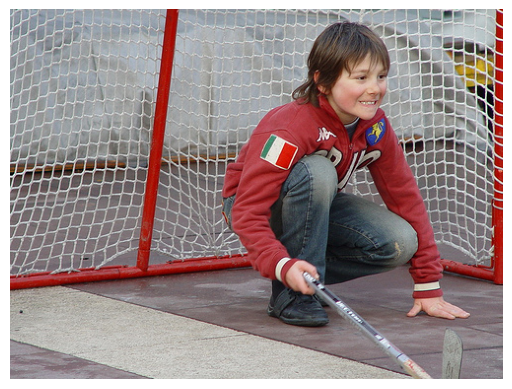

Generated: two young boys play on a trampoline
Reference: A boy with a stick kneeling in front of a goalie net


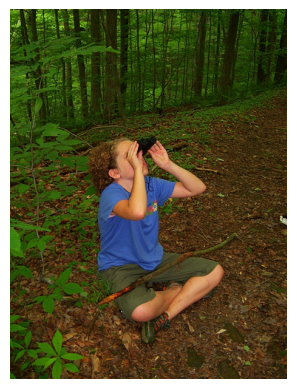

Generated: a young boy in a red shirt is jumping in the air
Reference: A child in a blue shirt sitting on a forest floor , looking through binoculars .


In [98]:
for filename in random.sample(val_images, 3):
    plt.imshow(Image.open(image_dir / filename).convert("RGB"))
    plt.axis("off")
    plt.show()

    print("Generated:", generate_caption(filename))
    print("Reference:", captions[filename][0])

In [99]:
from nltk.translate.bleu_score import corpus_bleu

val_predictions = {
    filename: tokenize(generate_caption(filename))
    for filename in val_images
}

references = [
    [tokenize(caption) for caption in captions[filename]]
    for filename in val_images
]

hypotheses = [
    val_predictions[filename]
    for filename in val_images
]

print(
    f"BLEU-1: {100 * corpus_bleu(references, hypotheses, weights=(1, 0, 0, 0)):.2f}"
)
print(
    f"BLEU-4: {100 * corpus_bleu(references, hypotheses):.2f}"
)

BLEU-1: 57.64
BLEU-4: 16.89
